# 02 · Volatilité implicite et smile

> 📘 Notebook compagnon du cours [Les grecques en finance](https://pgu.github.io/pi-gamma-upsilon/). Le code Python reproduit ce que font les playgrounds du site, avec les **mêmes conventions de desk** : vega par point de vol, theta par jour, rho par point de taux.
>
> **Installation** (une fois) : `pip install -r requirements.txt`, puis `jupyter lab`. Lance ce notebook depuis le dossier `notebooks/`.

**Leçons liées :** « Marché : la volatilité implicite », « smile, skew & term structure ».

**Objectifs :** inverser Black-Scholes pour retrouver σ à partir d'un prix, vérifier l'aller-retour, voir le smile, et traduire un écart bid/ask de **prix** en écart de **volatilité**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import greeks as g          # notre petite bibliothèque (voir greeks.py)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 1. Inverser Black-Scholes

Sur le marché on observe le **prix** ; la volatilité implicite est le σ qui redonne ce prix. Le prix est strictement croissant en σ (vega > 0) : la solution est unique et une méthode de bracketing (Brent) la trouve de façon fiable.

In [2]:
market_price = 2.40
iv = g.implied_vol(market_price, S=100, K=100, T=30/365, r=0.03, kind="call")
print(f"IV = {iv:.4%}")

# Aller-retour : on repasse l'IV dans Black-Scholes
back = float(g.price(100, 100, 30/365, 0.03, iv, "call"))
print(f"prix recalculé = {back:.6f}")
assert abs(back - market_price) < 1e-8

IV = 19.9160%
prix recalculé = 2.400000


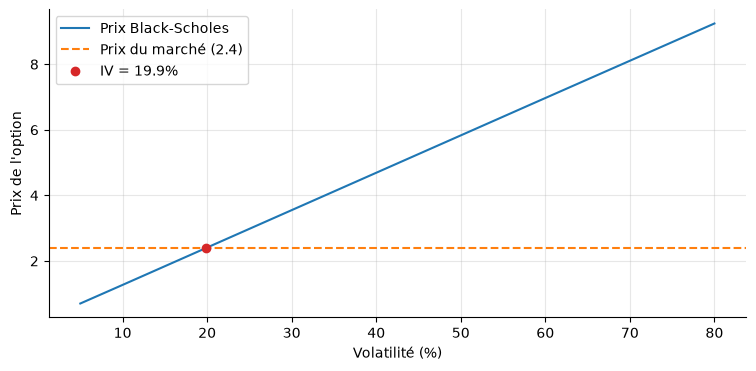

In [3]:
sigmas = np.linspace(0.05, 0.80, 200)
prices = [float(g.price(100, 100, 30/365, 0.03, s, "call")) for s in sigmas]

fig, ax = plt.subplots()
ax.plot(sigmas * 100, prices, label="Prix Black-Scholes")
ax.axhline(market_price, color="C1", ls="--", label=f"Prix du marché ({market_price})")
ax.plot([iv * 100], [market_price], "o", color="C3", label=f"IV = {iv:.1%}")
ax.set(xlabel="Volatilité (%)", ylabel="Prix de l'option")
ax.legend();

Un prix hors des bornes d'arbitrage n'a **pas** d'IV : la fonction renvoie `NaN`.

In [4]:
print(g.implied_vol(0.0001, S=100, K=50, T=30/365, r=0.03, kind="call"))   # sous la valeur intrinsèque → nan

nan


## 2. Le smile (modèle de marché simulé)

On génère des IV avec la même forme que dans le cours (skew + courbure, **données simulées**), on en déduit des prix, puis on **retrouve** les IV en inversant : c'est exactement ce que fait un desk avec des cotations.

Convention de marché : on utilise les options **OTM** (puts sous le spot, calls au-dessus) car ce sont les plus liquides.

In [5]:
S0, T, r = 100, 60/365, 0.03
strikes = np.arange(80, 121, 5)
true_iv = g.smile_iv(S0, strikes, T, atm=0.20, skew=0.4, curv=1.0)

kinds = np.where(strikes < S0, "put", "call")
px = np.array([float(g.price(S0, K, T, r, s, k)) for K, s, k in zip(strikes, true_iv, kinds)])
recovered = np.array([g.implied_vol(p, S0, K, T, r, k) for p, K, k in zip(px, strikes, kinds)])

smile = pd.DataFrame({"strike": strikes, "type": kinds, "prix": px, "IV vraie": true_iv, "IV retrouvée": recovered})
assert np.allclose(true_iv, recovered, atol=1e-8)
smile

,strike,type,prix,IV vraie,IV retrouvée
0,80,put,0.1741,0.3170,0.3170
1,85,put,0.3005,0.2753,0.2753
2,90,put,0.6136,0.2428,0.2428
3,95,put,1.3664,0.2181,0.2181
4,100,call,3.4781,0.2000,0.2000
5,105,call,1.3627,0.1877,0.1877
6,110,call,0.3986,0.1804,0.1804
7,115,call,0.0910,0.1775,0.1775
8,120,call,0.0183,0.1784,0.1784


Skew put 90 - call 110 : 6.2 points de vol


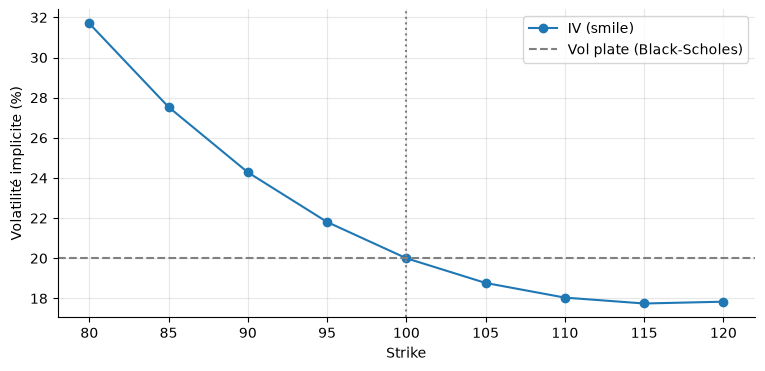

In [6]:
fig, ax = plt.subplots()
ax.plot(strikes, true_iv * 100, "o-", label="IV (smile)")
ax.axhline(20, color="gray", ls="--", label="Vol plate (Black-Scholes)")
ax.axvline(S0, color="gray", ls=":")
ax.set(xlabel="Strike", ylabel="Volatilité implicite (%)")
ax.legend()

skew = (true_iv[strikes == 90][0] - true_iv[strikes == 110][0]) * 100
print(f"Skew put 90 - call 110 : {skew:.1f} points de vol")

## 3. Bid/ask en prix ↔ bid/ask en vol

Les market makers cotent en **volatilité** (« 22,5 bid / 23,5 offer »). Un écart de prix de quelques centimes correspond à un écart de vol de plusieurs dixièmes de point : c'est le vega qui fait la conversion.

In [7]:
bid, ask = 2.35, 2.45
K, T = 100, 30/365
iv_bid = g.implied_vol(bid, 100, K, T, 0.03, "call")
iv_ask = g.implied_vol(ask, 100, K, T, 0.03, "call")
vega = float(g.greeks(100, K, T, 0.03, (iv_bid + iv_ask) / 2, "call")["vega"])

print(f"IV bid = {iv_bid:.2%}   IV ask = {iv_ask:.2%}   écart = {(iv_ask - iv_bid) * 100:.2f} pts de vol")
print(f"vega = {vega:.4f} par point  →  écart de prix / vega = {(ask - bid) / vega:.2f} pts (cohérent)")

IV bid = 19.48%   IV ask = 20.35%   écart = 0.88 pts de vol
vega = 0.1141 par point  →  écart de prix / vega = 0.88 pts (cohérent)


### À toi de jouer

1. Change `skew` à 0 et `curv` à 0 dans la section 2 : le smile devient-il plat ? Que vaut alors l'écart put 90 − call 110 ?
2. Calcule l'IV d'un **put** de strike 90 à partir de son prix, d'abord avec la vol ATM (20 %) puis avec l'IV du smile : de combien le prix est-il sous-estimé ?
3. *(Avancé)* Compare ton `implied_vol` avec celui de la bibliothèque `vollib` (`pip install vollib`) sur les mêmes cotations.